# Notebook 04: Benchmark Evaluation & Structure Analysis (E1–E3)

This notebook presents the empirical findings of the **LINEBENCH** assembly line balancing study:
- **Phase 4.1**: Standardized reference table with proven vs unproven labels and theoretical lower bounds.
- **Phase 4.2 (E1)**: Optimality gaps, hit rates, and runtimes across 13 heuristic methods and strata.
- **Phase 4.3**: Paired hypothesis tests (Wilcoxon signed-rank, Cohen's $d$, Holm-Bonferroni correction).
- **Phase 4.4 (E2)**: Structural regression analysis of gaps on Order Strength, size, and tightness.
- **Phase 4.5 (E3)**: Heuristic portfolio analysis vs exact benchmarks.
- **Phase 4.6**: Pass budget ($K$) ablation on randomized multi-pass.

> **Use Condition**: Regenerate any table or figure from the results log; slice results by stratum.

In [1]:
import sys
from pathlib import Path
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ensure project src is in sys.path
project_root = Path.cwd()
if not (project_root / 'src').exists() and (project_root.parent / 'src').exists():
    project_root = project_root.parent
if str(project_root / 'src') not in sys.path:
    sys.path.insert(0, str(project_root / 'src'))

from linebench.evaluation.benchmark import run_e1_evaluation_pipeline
from linebench.evaluation.compare import run_declared_paired_comparisons
from linebench.evaluation.structure import run_e2_structure_pipeline
from linebench.evaluation.portfolio_e3 import compute_e3_portfolio_metrics
from linebench.evaluation.ablations import run_ablation_pipeline

print('Benchmark evaluation modules loaded successfully!')

Benchmark evaluation modules loaded successfully!


## 1. Load & Inspect Reference Table (Phase 4.1)

Every benchmark instance has a pre-declared reference value (proven optimum $m^*$ or best-known bound),
theoretical lower bounds ($LB_1$, $LB_2$, $LB = \max(LB_1, LB_2)$), and size tier classifications.

In [2]:
ref_df = pd.read_csv(project_root / 'results' / 'reference_table.csv')
print(f'Total benchmark instances: {len(ref_df)}')
print(f'Proven optimal references: {ref_df["is_proven"].sum()} / {len(ref_df)}')
print(f'Unproven (best-known):     {(~ref_df["is_proven"]).sum()} / {len(ref_df)}')

print('\nBreakdown by Stratum & Size Tier:')
print(ref_df.groupby(['stratum', 'size_tier'])['instance_id'].count().unstack().fillna(0).astype(int))

ref_df.head(10)

Total benchmark instances: 395
Proven optimal references: 360 / 395
Unproven (best-known):     35 / 395

Breakdown by Stratum & Size Tier:
size_tier  large  medium  small  very_large
stratum                                    
classical    100      66     33           7
generated     63      63     63           0


,instance_id,stratum,num_tasks,cycle_time,size_tier,reference_stations,is_proven,lower_bound_1,lower_bound_2,lower_bound,lb_gap_stations,lb_relative_gap,source_file,cell
0,scholl_arcus1_c3786,classical,83,3786,large,21,True,20,5,20,1,0.047619,data/raw/scholl1993/precedence graphs/ARC83.IN2,NaN
1,scholl_arcus1_c3985,classical,83,3985,large,20,True,19,5,19,1,0.050000,data/raw/scholl1993/precedence graphs/ARC83.IN2,NaN
2,scholl_arcus1_c4206,classical,83,4206,large,19,True,18,4,18,1,0.052632,data/raw/scholl1993/precedence graphs/ARC83.IN2,NaN
3,scholl_arcus1_c4454,classical,83,4454,large,18,True,17,4,17,1,0.055556,data/raw/scholl1993/precedence graphs/ARC83.IN2,NaN
4,scholl_arcus1_c4732,classical,83,4732,large,17,True,16,3,16,1,0.058824,data/raw/scholl1993/precedence graphs/ARC83.IN2,NaN
5,scholl_arcus1_c5048,classical,83,5048,large,16,True,15,3,15,1,0.062500,data/raw/scholl1993/precedence graphs/ARC83.IN2,NaN
6,scholl_arcus1_c5408,classical,83,5408,large,15,True,14,2,14,1,0.066667,data/raw/scholl1993/precedence graphs/ARC83.IN2,NaN
7,scholl_arcus1_c5824,classical,83,5824,large,14,True,13,1,13,1,0.071429,data/raw/scholl1993/precedence graphs/ARC83.IN2,NaN
8,scholl_arcus1_c5853,classical,83,5853,large,14,True,13,1,13,1,0.071429,data/raw/scholl1993/precedence graphs/ARC83.IN2,NaN
9,scholl_arcus1_c6309,classical,83,6309,large,13,True,12,1,12,1,0.076923,data/raw/scholl1993/precedence graphs/ARC83.IN2,NaN


## 2. E1: Heuristic Performance Evaluation by Method & Stratum (Phase 4.2)

Evaluates station gap ($m - m^*$), relative gap (%), hit rate (%), and runtime (ms) across all 5,135 runs.

In [3]:
# Method summary table
method_summary = pd.read_csv(project_root / 'results' / 'e1_method_summary.csv')
print('--- Heuristic Performance Summary (Sorted by Relative Gap %) ---')
display_cols = ['method', 'hit_rate_pct', 'mean_gap', 'median_gap', 'mean_relative_gap_pct', 'mean_runtime_ms']
method_summary[display_cols]

--- Heuristic Performance Summary (Sorted by Relative Gap %) ---


,method,hit_rate_pct,mean_gap,median_gap,mean_relative_gap_pct,mean_runtime_ms
0,MULTI_PASS_RPW_K500,69.873418,0.718987,0.0,2.615332,854.580536
1,UBT_BACKWARD,53.417722,1.000000,0.0,4.783063,8.526225
2,RPW_FORWARD,57.468354,0.982278,0.0,4.857620,0.629529
3,UBT_FORWARD,52.911392,0.982278,0.0,4.974518,0.509440
4,RPW_BACKWARD,51.645570,1.055696,0.0,5.048531,8.810268
5,MTS_FORWARD,48.354430,1.200000,1.0,5.963735,0.499164
6,LST_BACKWARD,45.569620,1.200000,1.0,6.102546,8.533463
7,MTS_BACKWARD,44.050633,1.230380,1.0,6.114076,8.434839
8,LST_FORWARD,46.582278,1.167089,1.0,6.415346,0.725534
9,MDS_FORWARD,41.772152,1.356962,1.0,7.085120,0.456308


In [4]:
# Stratified summary (Stratum x Size Tier)
stratum_summary = pd.read_csv(project_root / 'results' / 'e1_stratum_summary.csv')
print('--- Top Heuristic (MULTI_PASS_RPW_K500) Performance Across Strata ---')
top_strat = stratum_summary[stratum_summary['method'] == 'MULTI_PASS_RPW_K500']
top_strat[['stratum', 'size_tier', 'instance_count', 'hit_rate_pct', 'mean_gap', 'mean_relative_gap_pct', 'mean_runtime_ms']]

--- Top Heuristic (MULTI_PASS_RPW_K500) Performance Across Strata ---


,stratum,size_tier,instance_count,hit_rate_pct,mean_gap,mean_relative_gap_pct,mean_runtime_ms
8,classical,large,100,71.000000,0.360000,1.534288,1201.488180
21,classical,medium,66,68.181818,0.378788,2.527566,516.918733
34,classical,small,33,100.000000,0.000000,0.000000,135.393161
47,classical,very_large,7,0.000000,1.571429,4.242436,5335.906129
60,generated,large,63,46.031746,2.206349,5.014071,1357.687840
73,generated,medium,63,60.317460,1.095238,4.866961,668.127708
86,generated,small,63,95.238095,0.063492,0.962001,219.812071


### E1 Diagnostic Figures
- Boxplot of optimality gap distributions across all 13 heuristic rules.
- Hit rate comparison stratified by problem size tier.

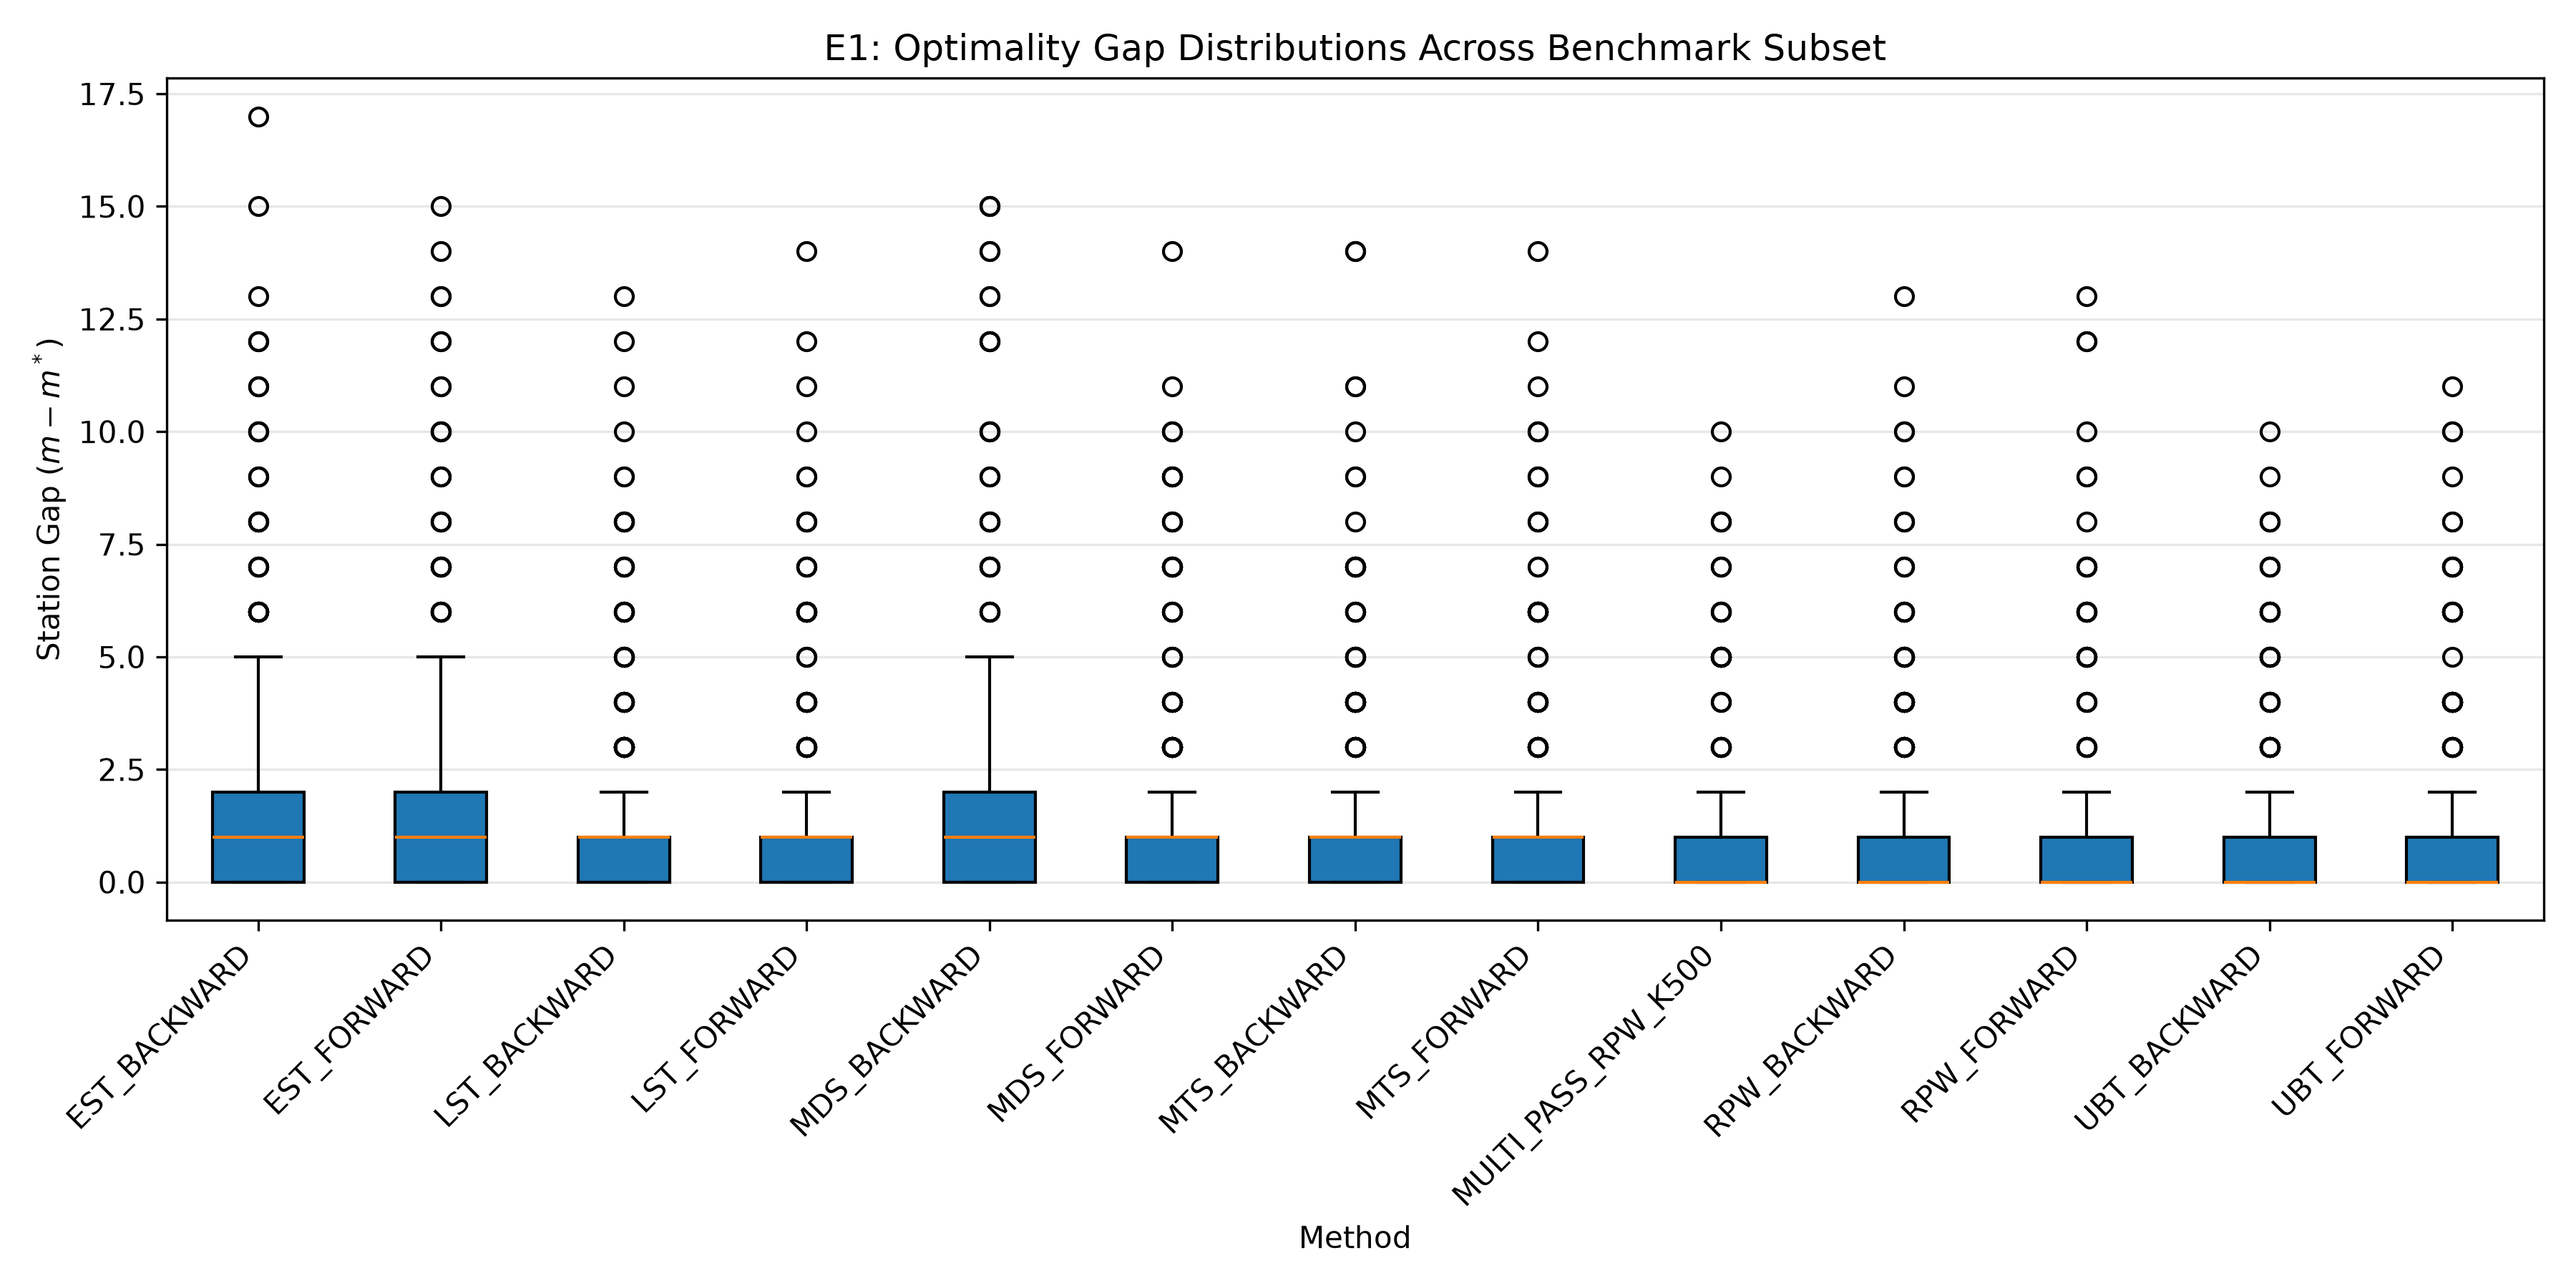

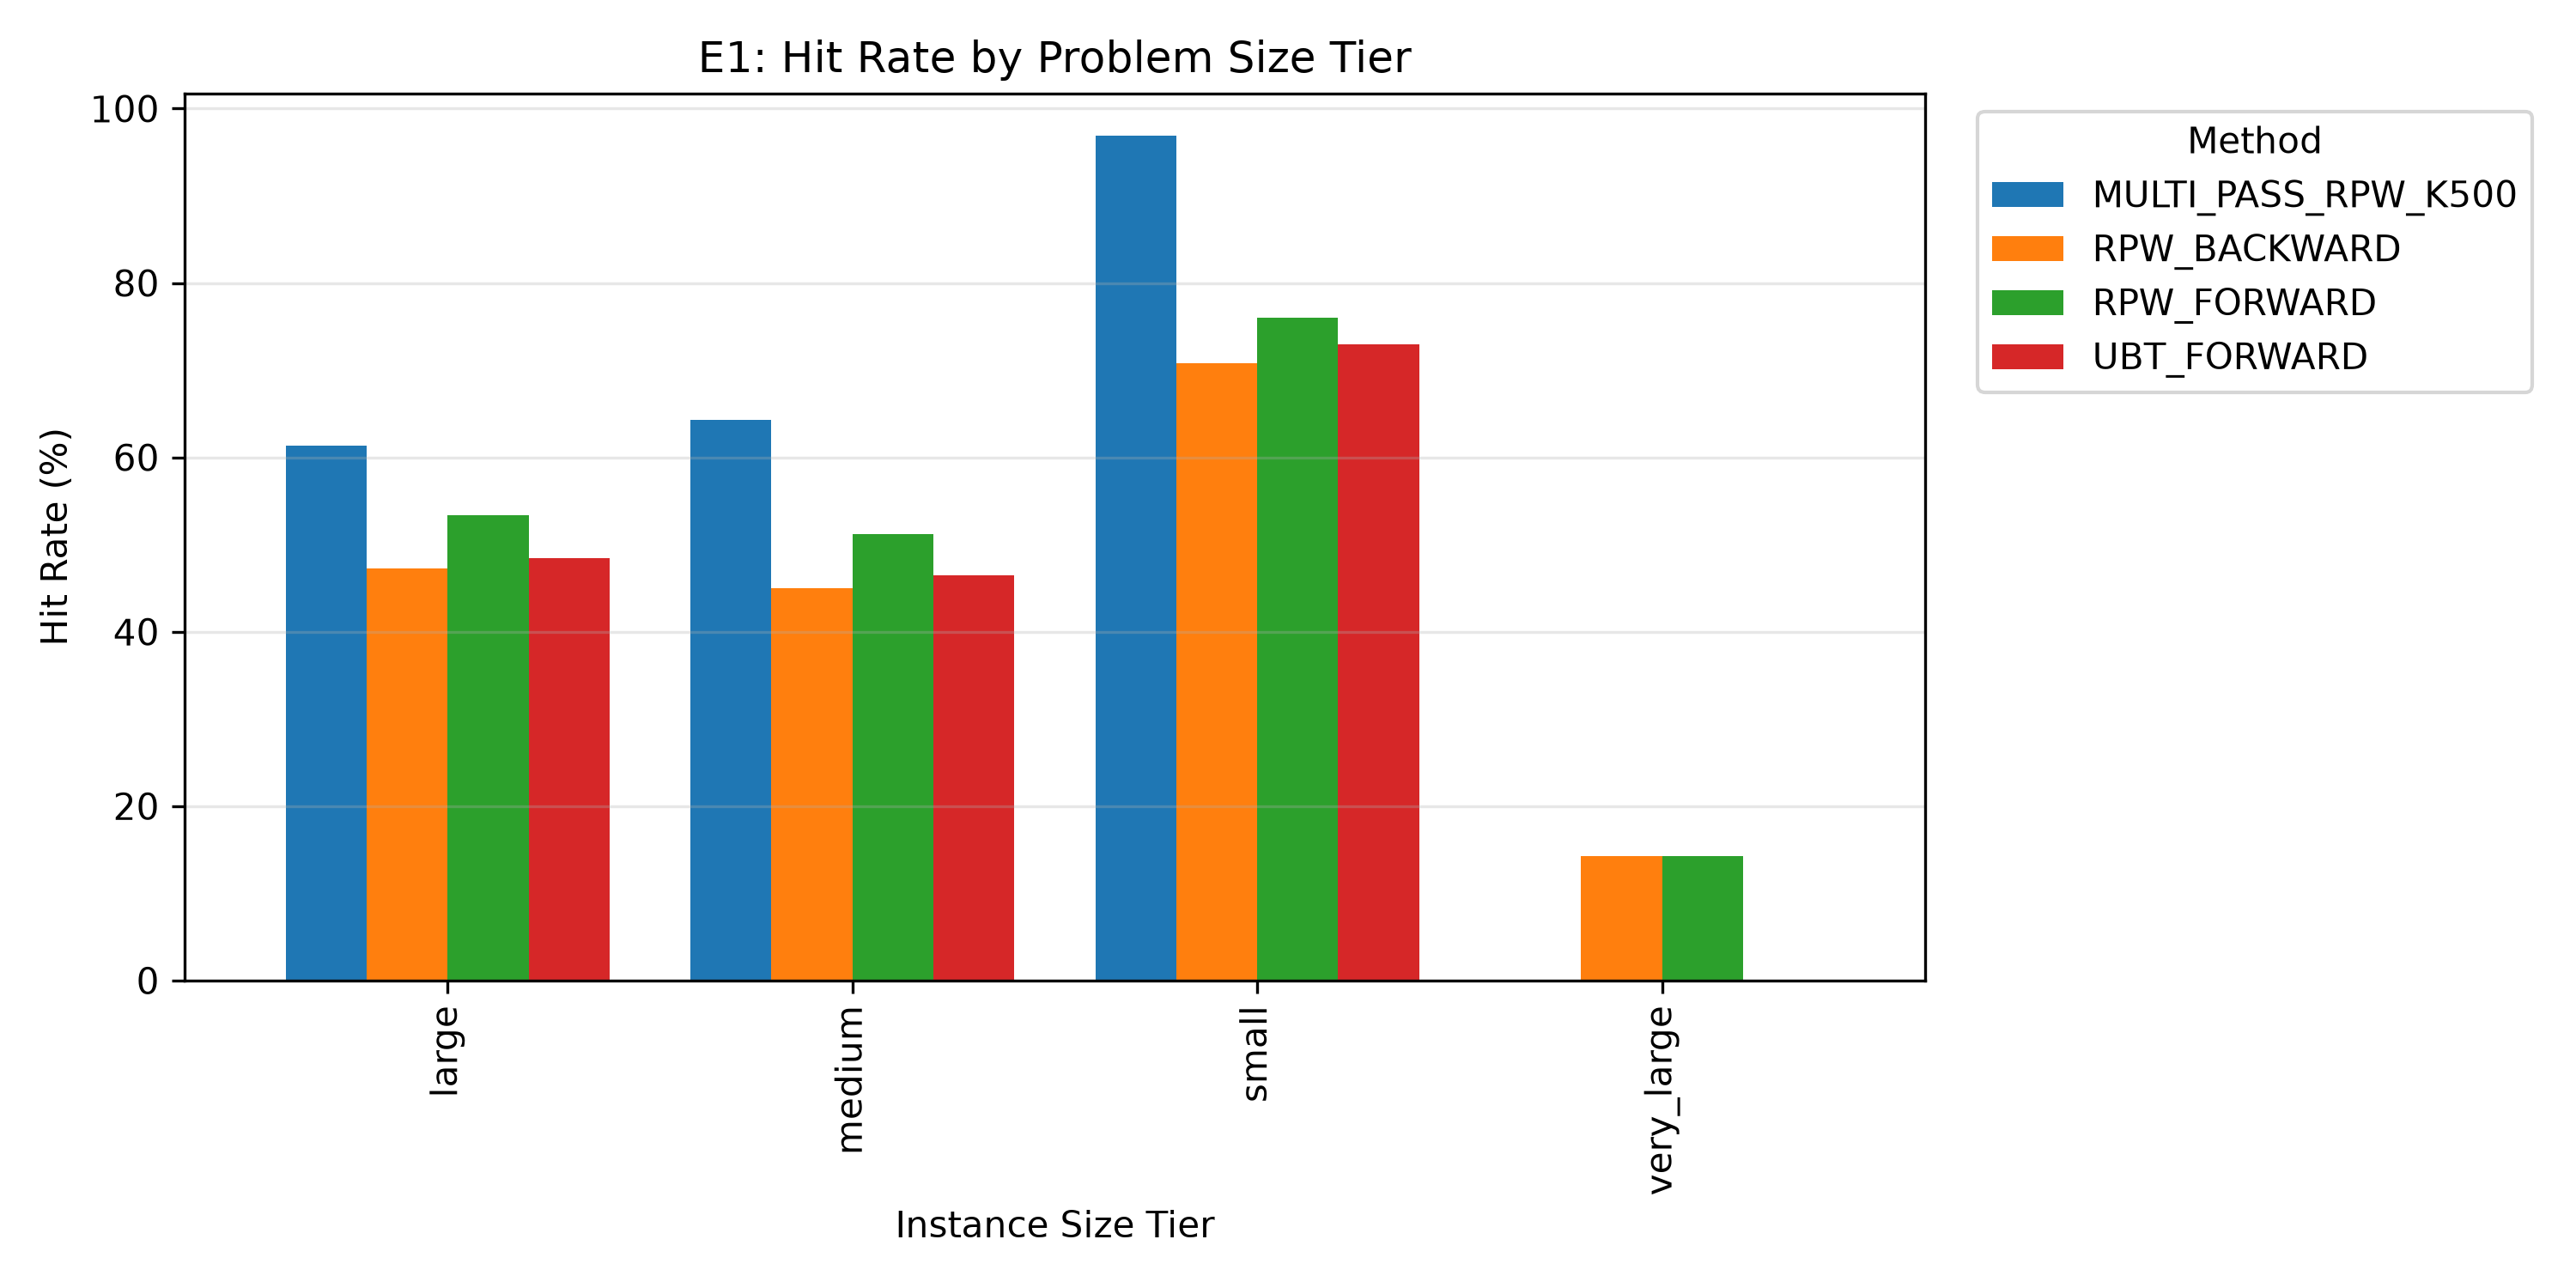

In [5]:
from IPython.display import Image, display
display(Image(filename=str(project_root / 'results' / 'figures' / 'e1_gap_distributions.png')))
display(Image(filename=str(project_root / 'results' / 'figures' / 'e1_hit_rate_by_size.png')))

## 3. Paired Statistical Comparisons with Effect Sizes (Phase 4.3)

Rigorous non-parametric Wilcoxon signed-rank tests with matched-pairs rank biserial $r$,
paired Cohen's $d_z$, and **Holm-Bonferroni family-wise error rate adjustment**.

In [6]:
df_paired = pd.read_csv(project_root / 'results' / 'paired_comparisons.csv')
print('--- Paired Head-to-Head Comparisons Across 395 Instances ---')
pair_cols = ['method_a', 'method_b', 'wins_a', 'ties', 'losses_a', 'mean_diff', 'cohens_d', 'wilcoxon_p_value', 'p_adjusted_holm', 'significant_at_05']
df_paired[pair_cols]

--- Paired Head-to-Head Comparisons Across 395 Instances ---


,method_a,method_b,wins_a,ties,losses_a,mean_diff,cohens_d,wilcoxon_p_value,p_adjusted_holm,significant_at_05
0,RPW_FORWARD,UBT_FORWARD,73,257,65,0.000000,0.000000,5.523198e-01,1.000000e+00,False
1,RPW_FORWARD,RPW_BACKWARD,73,275,47,-0.073418,-0.100835,1.944744e-02,5.834233e-02,False
2,UBT_FORWARD,UBT_BACKWARD,62,275,58,-0.017722,-0.022665,7.002625e-01,1.000000e+00,False
3,MULTI_PASS_RPW_K500,RPW_FORWARD,97,282,16,-0.263291,-0.378532,2.359359e-14,9.437436e-14,True
4,MULTI_PASS_RPW_K500,UBT_BACKWARD,104,279,12,-0.281013,-0.438505,1.245138e-17,6.225690e-17,True
5,MULTI_PASS_RPW_K500,MTS_FORWARD,148,243,4,-0.481013,-0.618105,2.104480e-31,1.262688e-30,True
6,RPW_FORWARD,EST_FORWARD,193,190,12,-0.774684,-0.662368,1.812497e-36,1.268748e-35,True


## 4. E2: Instance Structural Regression Analysis (Phase 4.4)

Multivariate regression modeling heuristic gaps against DAG order strength, task count, cycle tightness, and task-time variance.

In [7]:
df_reg = pd.read_csv(project_root / 'results' / 'e2_regression_coefficients.csv')
print('--- Structural Regression Coefficients (Dependent Variable: Relative Gap %) ---')
df_reg

--- Structural Regression Coefficients (Dependent Variable: Relative Gap %) ---


,predictor,coefficient,std_error,t_stat,p_value,method
0,const,8.631792,1.725241,5.003237,8.545023e-07,RPW_FORWARD
1,order_strength,1.868354,1.810636,1.031878,3.027689e-01,RPW_FORWARD
2,num_tasks,-0.003724,0.008905,-0.418182,6.760440e-01,RPW_FORWARD
3,tightness_ratio,-0.591193,0.558405,-1.058718,2.903837e-01,RPW_FORWARD
4,task_time_cv,-6.050039,1.805262,-3.351335,8.827639e-04,RPW_FORWARD
5,const,5.768933,1.034673,5.575612,4.614112e-08,MULTI_PASS_RPW_K500
6,order_strength,1.728439,1.085886,1.591732,1.122552e-01,MULTI_PASS_RPW_K500
7,num_tasks,0.025789,0.005340,4.829110,1.973362e-06,MULTI_PASS_RPW_K500
8,tightness_ratio,-0.939661,0.334890,-2.805880,5.269402e-03,MULTI_PASS_RPW_K500
9,task_time_cv,-6.953259,1.082663,-6.422364,3.907908e-10,MULTI_PASS_RPW_K500


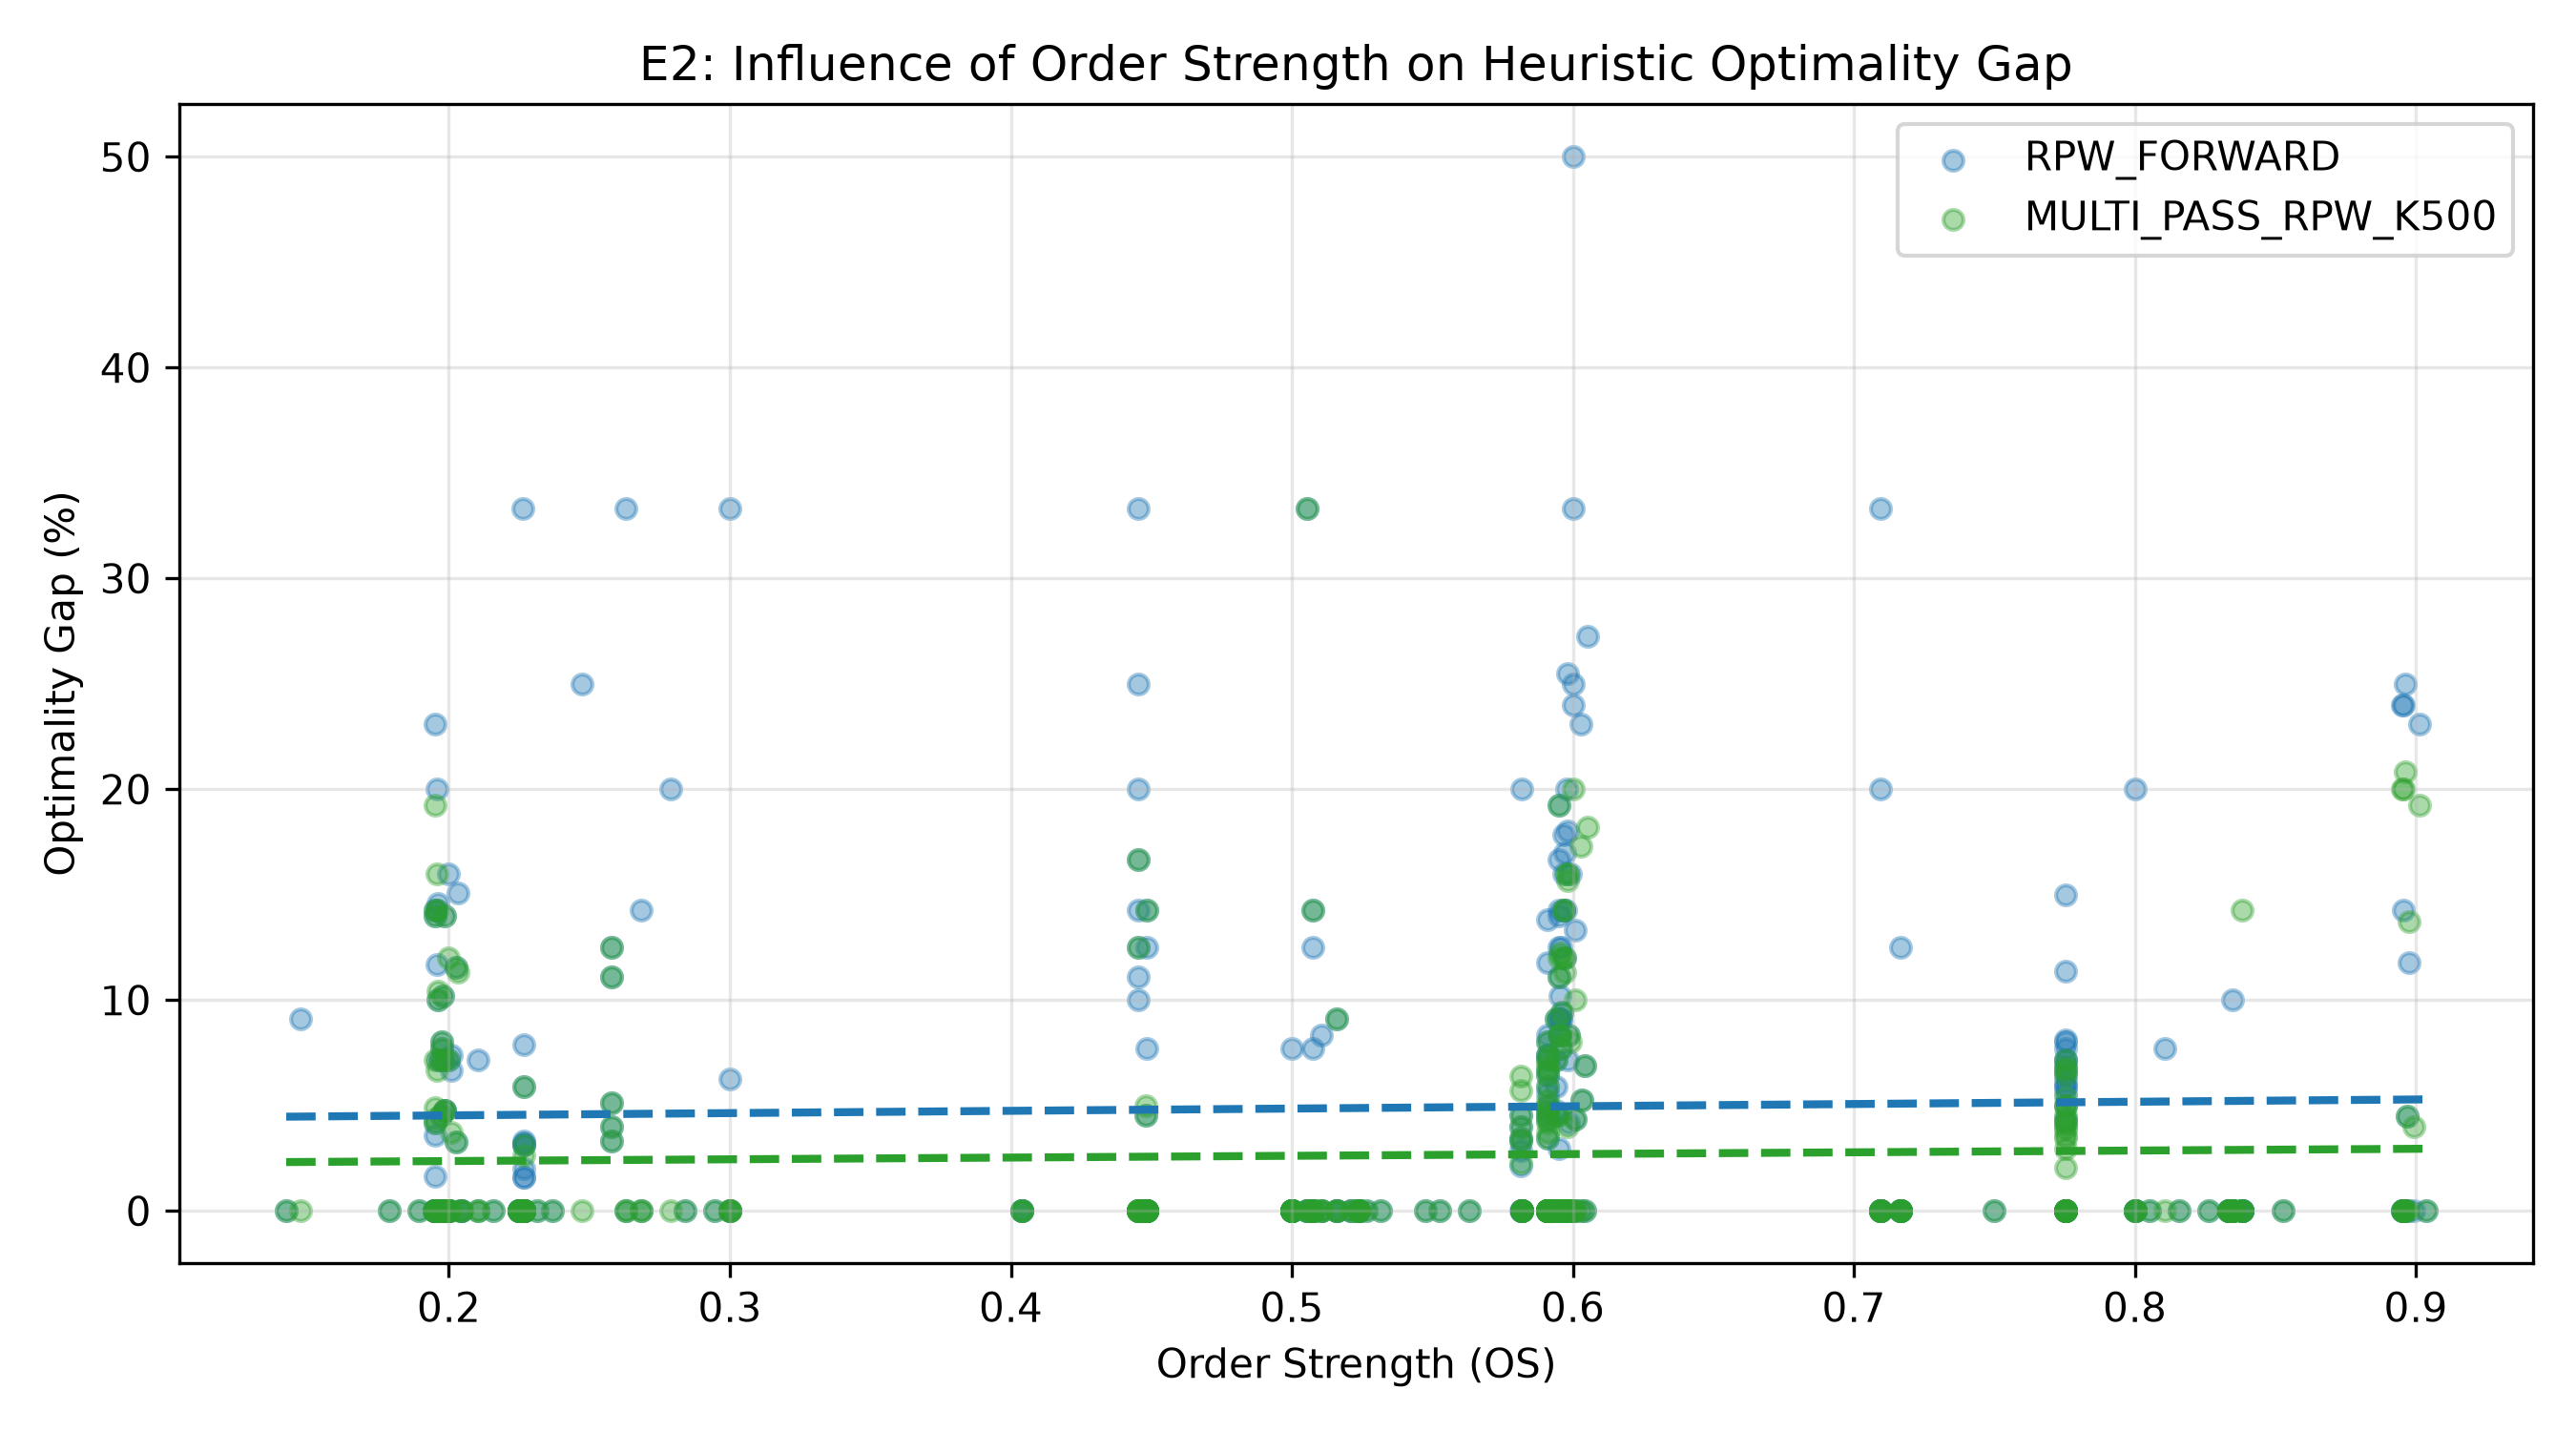

In [8]:
display(Image(filename=str(project_root / 'results' / 'figures' / 'e2_gap_vs_order_strength.png')))

## 5. E3: Portfolio Analysis (Phase 4.5)

Evaluates whether combining multiple heuristics matches the exact solver at a fraction of runtime.

In [ ]:
df_port = pd.read_csv(project_root / 'results' / 'e3_portfolio_summary.csv')
print('--- Portfolio Performance ---')
df_port[['portfolio_name', 'hit_rate_pct', 'mean_gap', 'mean_relative_gap_pct', 'total_runtime_seconds', 'mean_runtime_per_instance_ms']]

In [ ]:
display(Image(filename=str(project_root / 'results' / 'figures' / 'e3_portfolio_performance.png')))

## 6. Ablation: Multi-Pass Pass Budget ($K$) Scaling (Phase 4.6)

Analyzes diminishing returns in solution quality vs runtime scaling as $K$ increases from 10 to 500.

In [ ]:
df_ablation = pd.read_csv(project_root / 'results' / 'ablation_multipass_k.csv')
print('--- K-Pass Scaling Data ---')
df_ablation[['k_passes', 'mean_stations', 'mean_time_per_instance_ms', 'duration_seconds']]

In [ ]:
display(Image(filename=str(project_root / 'results' / 'figures' / 'ablation_multipass_k.png')))